# High resolution total alkalinity estimation using GLODAP2

In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import pathlib

import numpy as np
import pandas as pd
import xarray as xr
from matplotlib import pyplot as plt
from scipy.special import huber
from sklearn import metrics

import highres_ta as ta

In [3]:
from typing import Any


def scoring(y_true, y_pred) -> pd.DataFrame:
    from loguru import logger

    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)

    residuals = y_pred - y_true
    scores = pd.Series(
        {
            "root_mean_squared_error": metrics.root_mean_squared_error(y_true, y_pred),
            "mean_absolute_error": metrics.mean_absolute_error(y_true, y_pred),
            "huber_loss": huber(1.35, residuals).mean(),
            "median_absolute_error": metrics.median_absolute_error(y_true, y_pred),
            "mean_bias": residuals.mean(),
            "median_bias": np.median(residuals),
            "r2_score": metrics.r2_score(y_true, y_pred),
        },
    name='Scores').to_frame()
    scores.index.name = "Metric"

    logger.info(f"\n{scores.to_markdown(floatfmt='.3f')}")

    return scores


def load_model(model_path):
    model = ta.QuantileRegressionEnsemble.load(model_path)
    model.optimise_cpus(max_cpus=42)
    model.aggregation = "median"
    return model


def get_scores(y, yhat) -> pd.Series:

    scores = pd.Series()
    for metric_name in [
        "root_mean_squared_error",
        "mean_absolute_error",
        "median_absolute_error",
        "r2_score",
    ]:
        metric_func = getattr(metrics, metric_name)
        scores[metric_name] = metric_func(y, yhat)

    scores["mean_bias"] = (yhat - y).mean()
    scores["median_bias"] = np.median(yhat - y)

    return scores


def get_scores_by_filter(y_true: np.ndarray|pd.Series, y_pred: np.ndarray|pd.Series, filter_masks) -> pd.DataFrame:
    scores = pd.DataFrame()
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    for name, mask in filter_masks.items():
        mask = np.asarray(mask)
        scores[name] = get_scores(y_true[mask], y_pred[mask])

    return scores


def data_with_alternate_salinity(
    config: dict[str, Any], data: pd.DataFrame, salinity_new: str, salinity_original: str = "salinity"
) -> pd.DataFrame:
    """
    Return ``data`` with the salinity column swapped for ``salinity_new``.

    Rows (and their order) are kept identical to ``data`` so that the positional
    ``row_id``s in the saved split files remain valid. Values of the alternate product
    outside the training salinity range are set to NaN, as are missing values; those
    rows are dropped later in ``load_saved_splits`` via ``non_null_columns``.
    """
    if salinity_new == salinity_original:
        return data.copy()

    data_config = config["data"]
    raw = ta.load_data(str(ta.resolve_path(config["paths"]["training_data"]))).set_index(
        data_config["coordinate_columns"]
    )
    raw = raw[~raw.index.duplicated(keep="first")]

    salinity = raw[salinity_new].reindex(data.index)
    in_range = salinity.between(data_config["minimum_salinity"], data_config["maximum_salinity"])
    return data.assign(**{salinity_original: salinity.where(in_range).to_numpy()})


In [4]:
FNAME_MODEL = "../models/quantile_ensemble_split_hpo/models/quantile_ensemble.joblib"
FNAME_PROCESSED = "/net/sea/work/gregorl/projects/oceansoda_v2/data/processed/OceanSODA_ETHZv2-gridded_data-8D_025deg.zarr"
FNAME_BATHYMETRY = "/net/sea/work/datasets/grd/ocean/2d/obs/bathymetry/ETOPO1/ETOPO15_mean_bath.nc"
FNAME_NUTRIENTS = "/net/sea/work/gregorl/projects/OceanSODA-ETHZv2/data-in/carbsys/nutrients_woa18_t46y720x1440.zarr"

MAX_CPUS = 42

In [5]:
model = load_model(FNAME_MODEL)
features_ds = ta.open_inference_data(x_names=model.get_feature_names())

# Training/Test Data

In [6]:
config = ta.load_config()
data = ta.prepare_data(config, show_all_columns=False)

2026-10-16 17:51:17.458 | DEBUG    | highres_ta.dataio:load_data:18 - Loading 40 .pq files from /net/sea/work/gregorl/projects/highres_TA/data/training


2026-10-16 17:51:18.021 | DEBUG    | highres_ta.target_filtering:drop_bad_quality_talk:49 - TA values with large adjustments (<= 6.0 mol/kg): 2365
2026-10-16 17:51:18.023 | DEBUG    | highres_ta.target_filtering:drop_bad_quality_talk:52 - TA values without good flags (!= 2): 3046
2026-10-16 17:51:18.024 | INFO     | highres_ta.target_filtering:drop_bad_quality_talk:53 - Number of rows filtered due to large adjustments and bad flags: 5319 of 41534 (13%)
2026-10-16 17:51:18.097 | INFO     | train_quantile_ensemble:prepare_data:132 - Prepared 28,988 observations with 10 features


In [ ]:
from dataclasses import dataclass

from loguru import logger


@dataclass
class SubsetData:
    name: str
    x: pd.DataFrame
    y: pd.Series

    def __repr__(self):
        return f"SubsetData(name={self.name}, x={self.x.shape}, y={self.y.shape}, target_name={self.y.name}, feature_names={list(self.x.columns)})"

    def __getitem__(self, idx):
        return getattr(self, idx)

@dataclass
class SubsetCollection:
    train: SubsetData
    test: SubsetData
    validation: SubsetData

    def __repr__(self):
        n_train = len(self.train.x)
        n_test = len(self.test.x)
        n_validation = len(self.validation.x)
        return f"SubsetCollection(train={n_train}, test={n_test}, validation={n_validation})"

    def __getitem__(self, idx):
        return getattr(self, idx)

    @property
    def valid(self):
        """Alias for validation set."""
        return self.validation

@dataclass
class SplitCollection:
    splits: list[SubsetCollection]
    split_ids: list[int]
    test_is_validated: bool = False

    def __getitem__(self, idx):
        return self.splits[idx]

    @property
    def n_splits(self):
        return len(self.splits)

    def __repr__(self):
        text = "SplitCollection(\n"
        for i, split in zip(self.split_ids, self.splits):
            text += f"  {i}: {split}\n"
        text += ")"
        return text

    @classmethod
    def from_flist(cls, flist: str | list[str], config: dict, data: pd.DataFrame):
        import glob
        import re

        if isinstance(flist, str) and "*" in flist:
            flist = list(glob.glob(flist))
        elif isinstance(flist, list):
            pass
        else:
            raise ValueError("flist must be a string with a wildcard or a list of strings.")

        # split id is parsed from the file name (split_<k>.parquet); glob order is arbitrary
        def split_id(fname: str) -> int:
            match = re.search(r"split_(\d+)\.parquet$", fname)
            if match is None:
                raise ValueError(f"Cannot parse split id from {fname}")
            return int(match.group(1))

        flist = sorted(flist, key=split_id)
        split_ids = [split_id(fname) for fname in flist]
        splits = [load_saved_splits(fname, config, data) for fname in flist]

        return cls(splits=splits, split_ids=split_ids)

    def validate_test(self):
        if self.test_is_validated:
            logger.info("Test sets have already been validated.")
            return
        
        if not self.splits:
            return

        index0 = self.splits[0].test.y.index
        indices = [split.test.y.index.equals(index0) for split in self.splits[1:]]

        if not all(indices):
            raise ValueError("Test sets are not consistent across splits.")
        else:
            self.test_is_validated = True
            logger.success("Test sets are consistent across splits.")

    @property
    def test(self):
        """
        Returns the test set from the first split after validating that all test sets are consistent.
        """
        if not self.test_is_validated:
            raise ValueError("Test sets have not been validated. Call validate_test() first.")
        
        return self.splits[0].test


def load_saved_splits(pq_fname_split: str, config: dict, data: pd.DataFrame): 
    split_frame = pd.read_parquet(pq_fname_split)

    # row_id is a position into the data the ensemble was trained on, so ``data`` must
    # have exactly the same rows in the same order
    if len(split_frame) != len(data):
        raise ValueError(
            f"{pq_fname_split} has {len(split_frame)} rows but data has {len(data)}; "
            "row_ids would point at the wrong observations."
        )
    expocodes = data.index.get_level_values("expocode").to_numpy()[split_frame.row_id]
    if not (expocodes == split_frame.expocode.to_numpy()).all():
        raise ValueError(f"Expocodes in {pq_fname_split} do not match data rows.")

    target_name = config["data"]["target_name"]
    feature_names = config["data"]["feature_names"]
    non_null_columns = config["data"]["non_null_columns"]

    subsets_dict = {}

    for subset_name in split_frame.split.unique():
        subset_idx = split_frame.row_id[split_frame.split == subset_name].to_numpy()
        # drops rows where e.g. an alternate salinity product is missing
        subset_data = data.iloc[subset_idx].dropna(subset=non_null_columns)

        subset_x = subset_data[feature_names]
        subset_y = subset_data[target_name]

        subsets_dict[subset_name] = SubsetData(name=subset_name, x=subset_x, y=subset_y)

    return SubsetCollection(
        train=subsets_dict["train"],
        test=subsets_dict["test"],
        validation=subsets_dict["validation"]
    )


def make_region_masks(df: pd.DataFrame, depth_threshold: float = 500) -> dict[str, np.ndarray]:
    df = df.reset_index()

    coastal = df.bottomdepth.abs() <= depth_threshold
    highlat = df.lat.abs() >= 60

    filters = {
        "all": np.ones_like(highlat, dtype=bool),
        "coastal": coastal,
        "oceanic": ~coastal,
        "oceanic & < 60deg": ~coastal & ~highlat,
        "coastal & < 60deg": coastal & ~highlat,
        "coastal & > 60deg": coastal & highlat,
        "> 60deg": highlat,
    }

    return filters


def plot_region_masks(region_mask: dict[str, np.ndarray], df: pd.DataFrame, ax=None, **kwargs):
    from cartopy import crs as ccrs
    from cartopy import feature as cfeature

    df = df.reset_index()

    if ax is None:
        fig, ax = plt.subplots(figsize=(10, 5), subplot_kw={"projection": ccrs.PlateCarree()})
    else: 
        fig = ax.get_figure()

    props = {"s": 3, "transform": ccrs.PlateCarree()} | kwargs
    for name, mask in region_mask.items():
        if (">" in name) or ("<" in name):
            ax.scatter(df.lon[mask], df.lat[mask], label=name, **props)

    ax.coastlines(lw=0.5)
    ax.add_feature(cfeature.LAND, facecolor="0.9", zorder=0)
    ax.set_extent([-180, 180, -90, 90], crs=ccrs.PlateCarree())

    ax.set_xlabel("Longitude")
    ax.set_ylabel("Latitude")
    ax.set_title("Region Masks")
    ax.legend(markerscale=3, fontsize=8, framealpha=1, edgecolor="none", ncol=4)

    return fig, ax


@dataclass
class ValidationResults:
    x: pd.DataFrame
    y: pd.Series
    yhat: pd.Series
    resid: pd.Series


def predict_validation_splits(
    model: ta.QuantileRegressionEnsemble, splits: SplitCollection
) -> ValidationResults:

    """
    Predict each split's validation set with the median of the members trained on that
    split only (members of other splits used those rows for training).
    """
    validation_x = []
    validation_y = []
    validation_yhat = []
    validation_resid = []

    member_splits = np.asarray(model.member_splits)
    q50 = ta.quantile_column(model.quantiles, 0.5)

    for split_id, split in zip(splits.split_ids, splits.splits):
        members = [model.estimators[i] for i in np.flatnonzero(member_splits == split_id)]
        if not members:
            raise ValueError(f"No ensemble members found for split {split_id}.")

        valid = split.validation
        yhat_members = np.stack([member.predict_quantiles(valid.x) for member in members])
        yhat_q50 = np.median(yhat_members, axis=0)[:, q50]
        v_yhat = pd.Series(yhat_q50, index=valid.y.index, name="yhat")

        validation_x.append(valid.x)
        validation_y.append(valid.y)
        validation_yhat.append(v_yhat)
        validation_resid.append(v_yhat - valid.y)

    x = pd.concat(validation_x, axis=0)
    y = pd.concat(validation_y, axis=0)
    yhat = pd.concat(validation_yhat, axis=0)
    resid = pd.concat(validation_resid, axis=0)

    return ValidationResults(x=x, y=y, yhat=yhat, resid=resid)


def plot_series(series: pd.Series, reset_index: bool = True, x="lon", y="lat", **kwargs):
    import cartopy.crs as ccrs
    from cartopy import feature

    fig, ax = plt.subplots(figsize=(6.3, 3), dpi=200, subplot_kw={"projection": ccrs.PlateCarree(205)}, constrained_layout=True)

    if reset_index:
        series = series.reset_index()

    defaults = {
        "x": x,
        "y": y,
        "c": "plotting_var",
        "cmap": "RdYlBu_r",
        "vmin": -20,
        "vmax": 20,
        "s": 2,
        "ax": ax,
        "transform": ccrs.PlateCarree()
    }

    series.plot.scatter(**defaults | kwargs)
    
    ax.coastlines(lw=0.5)
    ax.add_feature(feature.LAND, facecolor="0.95", zorder=0)

    return fig, ax

# Test scores

In [8]:
splits = SplitCollection.from_flist("../models/quantile_ensemble_split_hpo/splits/split_*.parquet", config, data)
splits.validate_test()

2026-10-16 17:51:18.406 | SUCCESS  | __main__:validate_test:98 - Test sets are consistent across splits.


In [9]:
test_yhat = model.predict_members(splits.test.x)
test_yhat_da = xr.DataArray(
    test_yhat, 
    dims=["member", "sample", "quantile"], 
    coords={
        "member": np.arange(test_yhat.shape[0]), 
        "sample": np.arange(test_yhat.shape[1]), 
        "quantile": model.quantiles}
)

,all,coastal,oceanic,oceanic & < 60deg,coastal & < 60deg,coastal & > 60deg,> 60deg
root_mean_squared_error,20.390,24.882,18.530,14.542,25.445,24.211,27.992
mean_absolute_error,10.148,16.273,7.966,6.348,14.545,18.280,16.939
median_absolute_error,5.236,12.637,4.003,3.600,11.053,14.139,11.358
r2_score,0.954,0.898,0.965,0.968,0.847,0.873,0.923
mean_bias,0.710,6.404,-1.318,-1.698,6.247,6.587,3.458
median_bias,0.306,6.554,-0.397,-0.440,4.800,8.515,2.686


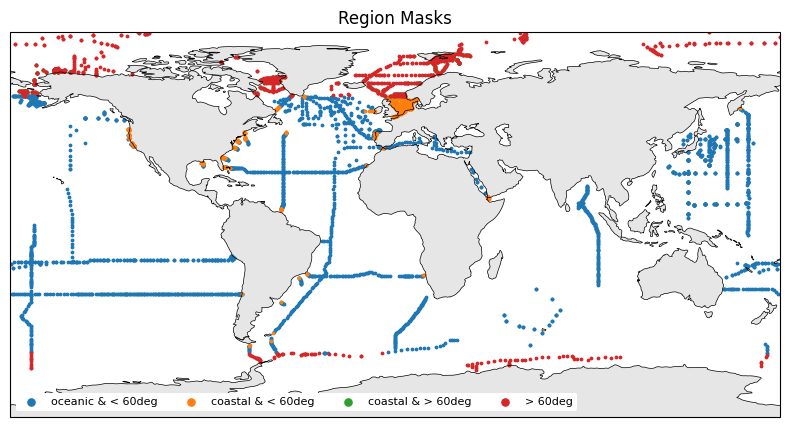

In [10]:
y = splits.test.y.values
yhat = test_yhat_da.sel(quantile=0.5).median("member").values

filters = make_region_masks(splits.test.x)

plot_region_masks(
    filters,
    splits.test.x,
)
get_scores_by_filter(y, yhat, filters).round(3)

# Validation Scores

,all,coastal,oceanic,oceanic & < 60deg,coastal & < 60deg,coastal & > 60deg,> 60deg
root_mean_squared_error,25.231,49.619,15.172,9.231,53.967,44.079,36.128
mean_absolute_error,10.010,25.732,6.509,5.067,23.712,28.061,18.892
median_absolute_error,4.200,12.561,3.534,3.243,10.768,16.217,8.829
r2_score,0.941,0.854,0.973,0.977,0.687,0.898,0.939
mean_bias,-0.682,-3.777,0.007,0.229,-7.972,1.058,-0.262
median_bias,0.065,-0.283,0.094,0.106,-0.382,-0.005,-0.023


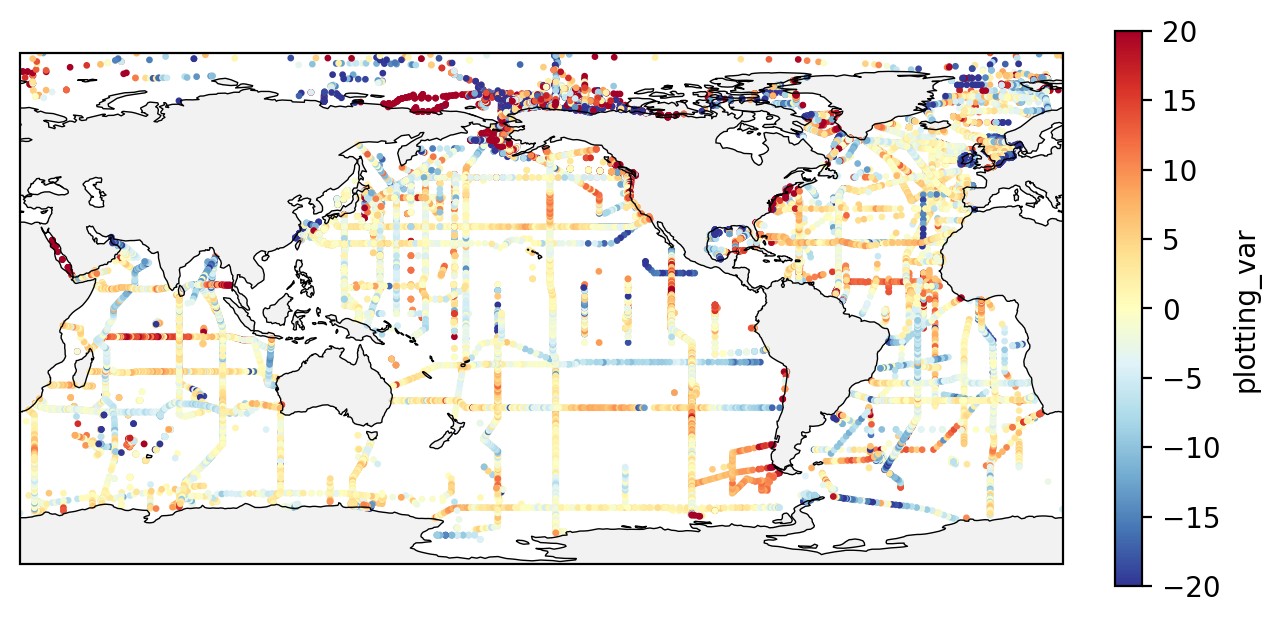

In [ ]:
valid = predict_validation_splits(model, splits)
mask_validation_data = make_region_masks(valid.x)
plot_series(valid.resid)
get_scores_by_filter(valid.y, valid.yhat, mask_validation_data).round(3)

# Alternate salinities

In [12]:
split_name = "../models/quantile_ensemble_split_hpo/splits/split_*.parquet"

scores = {}
splits_alts = {}
valid_alts = {}
for salt_name in ["salinity", "salt_soda", "sss_multiobs", "sss_cci"]:
    data_alt = data_with_alternate_salinity(config, data, salt_name)
    splits_alts[salt_name] = SplitCollection.from_flist(split_name, config, data_alt)

    valid = predict_validation_splits(model, splits_alts[salt_name])
    mask_validation_data = make_region_masks(valid.x)
    scores[salt_name] = get_scores_by_filter(valid.y, valid.yhat, mask_validation_data).round(3)
    valid_alts[salt_name] = valid


2026-10-16 17:52:22.981 | DEBUG    | highres_ta.dataio:load_data:18 - Loading 40 .pq files from /net/sea/work/gregorl/projects/highres_TA/data/training
2026-10-16 17:52:24.400 | DEBUG    | highres_ta.dataio:load_data:18 - Loading 40 .pq files from /net/sea/work/gregorl/projects/highres_TA/data/training
2026-10-16 17:52:25.617 | DEBUG    | highres_ta.dataio:load_data:18 - Loading 40 .pq files from /net/sea/work/gregorl/projects/highres_TA/data/training


In [35]:
scores["sss_multiobs"]

,all,coastal,oceanic,oceanic & < 60deg,coastal & < 60deg,coastal & > 60deg,> 60deg
root_mean_squared_error,43.389,76.488,31.315,20.669,59.368,91.918,73.071
mean_absolute_error,21.645,48.153,15.619,11.733,34.781,63.091,44.373
median_absolute_error,8.970,26.679,7.260,6.544,21.057,37.249,20.194
r2_score,0.825,0.632,0.889,0.885,0.588,0.534,0.748
mean_bias,-4.111,-12.498,-2.205,-3.193,-6.818,-18.845,-5.597
median_bias,-2.066,-9.039,-1.612,-1.597,-6.392,-13.520,-4.057


(<Figure size 1260x600 with 2 Axes>, <GeoAxes: xlabel='lon', ylabel='lat'>)

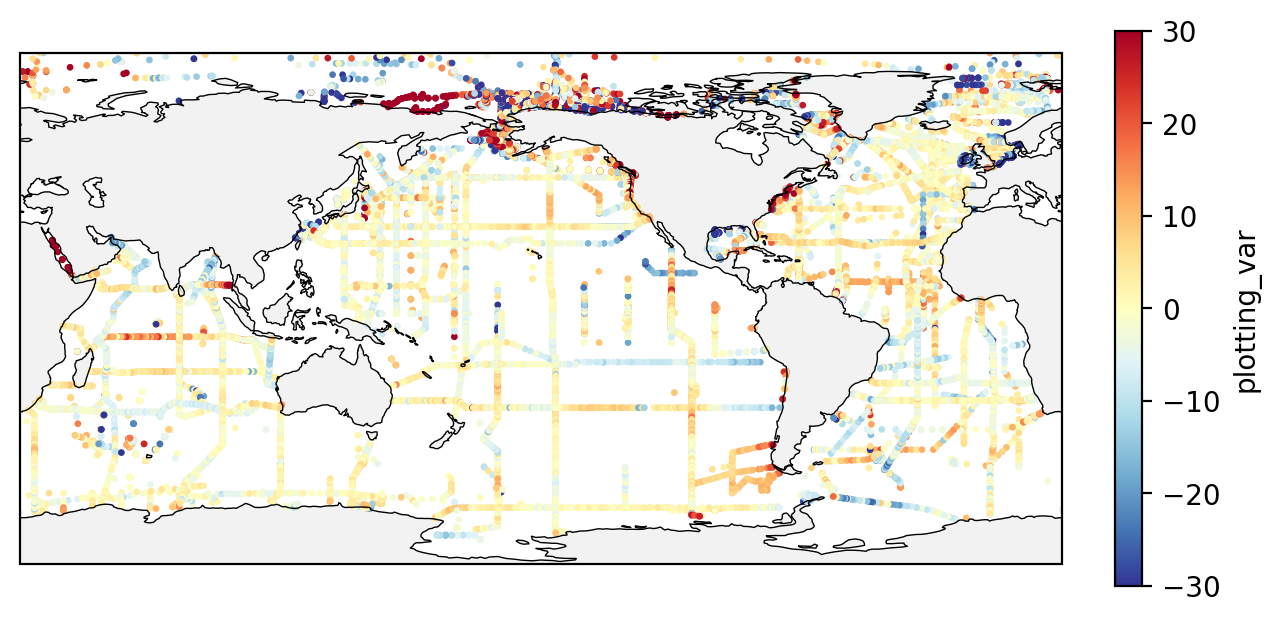

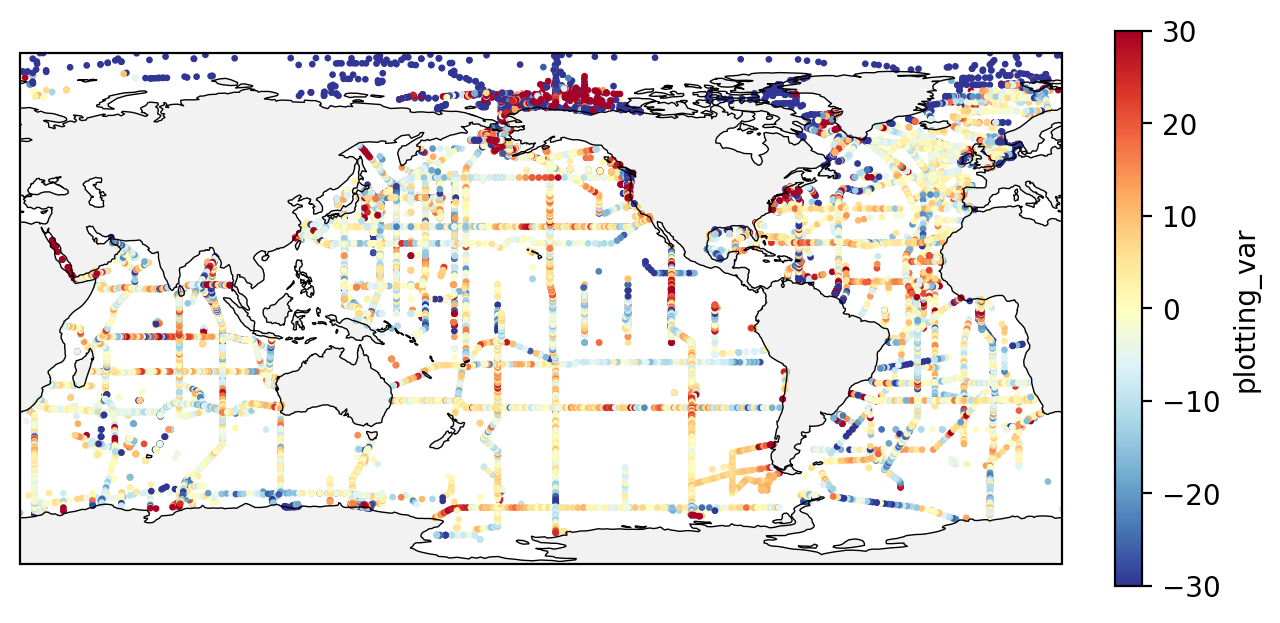

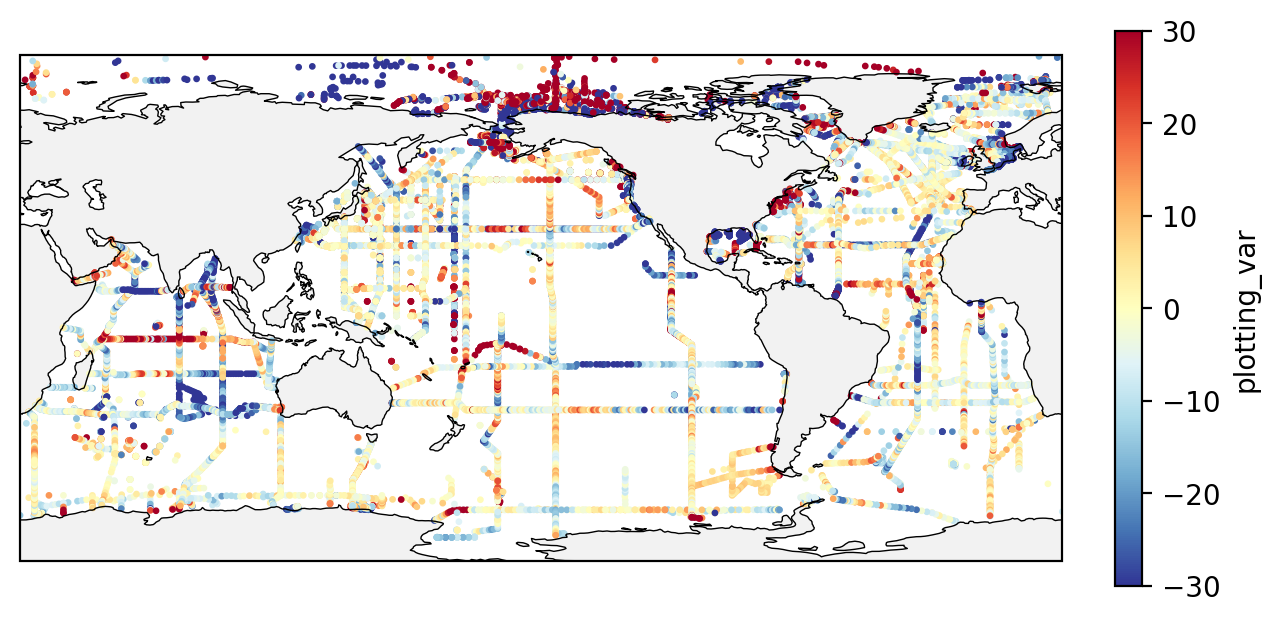

In [42]:
plot_series(valid_alts['salinity'].resid, vmin=-30, vmax=30)
plot_series(valid_alts['salt_soda'].resid, vmin=-30, vmax=30)
plot_series(valid_alts['sss_multiobs'].resid, vmin=-30, vmax=30)

(<Figure size 1260x600 with 2 Axes>, <GeoAxes: xlabel='lon', ylabel='lat'>)

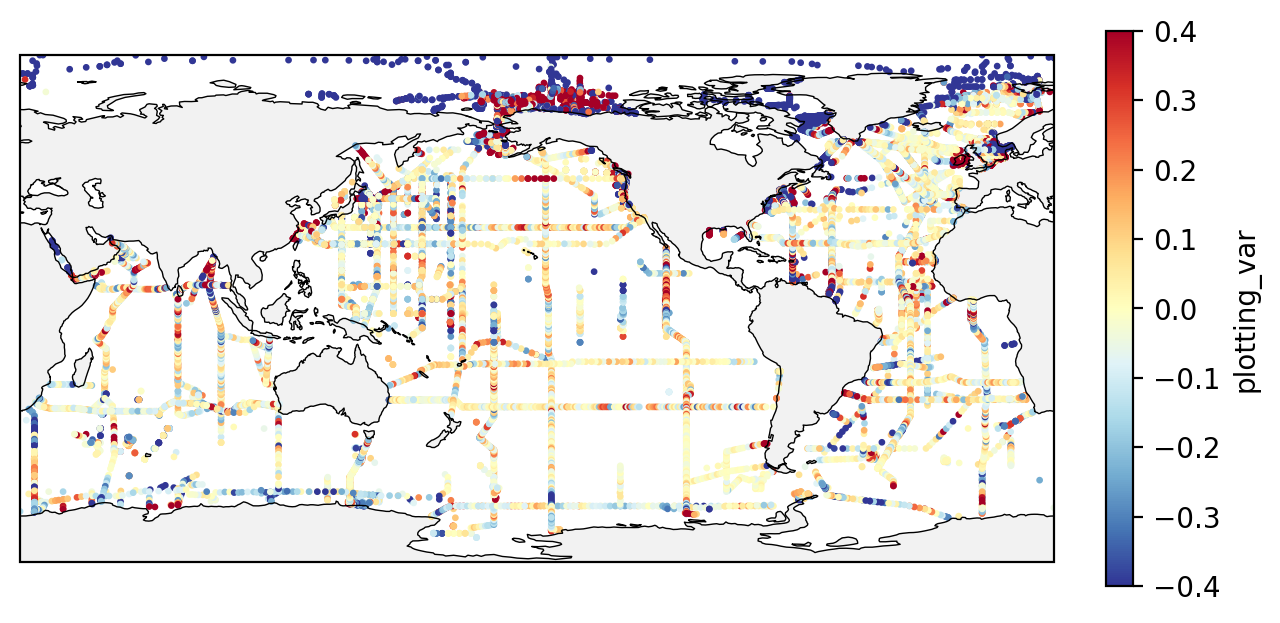

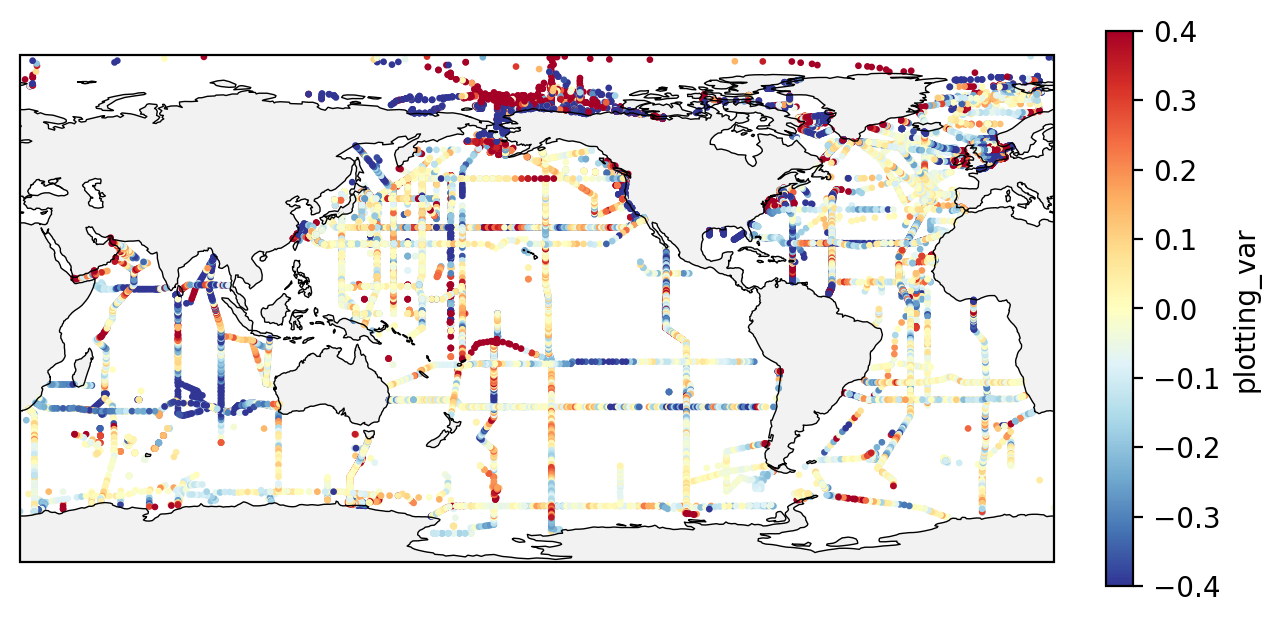

In [49]:
y = splits_alts['salinity'][0].train.x.salinity
plot_series(splits_alts['salt_soda'][0].train.x.salinity - y, vmin=-0.4, vmax=0.4)
plot_series(splits_alts['sss_multiobs'][0].train.x.salinity - y, vmin=-0.4, vmax=0.4)


In [1]:
import numpy as np

In [4]:
x = np.random.normal(loc=5, scale=1, size=1_000_000)

In [5]:
%timeit np.sqrt(x)
%timeit x ** 0.5

1.44 ms ± 3.03 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
1.31 ms ± 238 μs per loop (mean ± std. dev. of 7 runs, 1,000 loops each)
